# 07 · Post-evaluation: Analisis Kesalahan & Perbaikan
### BNI Ecosystem & Growth Intelligence — Kelompok 8 · ODP BNI Data Analytics Batch 2

| # | Notebook | Isi |
|---|---|---|
| 06 | Model Evaluation | champion XGBoost dinilai **sekali** di test — **angka resmi** |
| **07** | **Post-evaluation** | **notebook ini — mengapa model salah, audit label, perbaikan prospect & anomali (pasca-evaluasi, mode shadow)** |
| 08 | Segmentasi & Opportunity Score | K-means 3 segmen, skor per segmen |

## Aturan main pasca-evaluasi
1. **Angka resmi tetap NB06.** File `models/06_final/` tidak diubah; hash-nya dicek terhadap `evaluation_lock.json` di awal dan akhir notebook.
2. Semua perbaikan di sini **dipilih setelah test dibuka**, jadi diberi label **pasca-evaluasi** dan masuk **mode shadow**. Promosi menjadi champion baru sah bila sudah dinilai di data segar (batch nasabah berikutnya).
3. **Prospect**: metode koreksi dipilih dengan aturan yang **tidak memakai label prospect** (bagian E3). Label prospect hanya dipakai untuk melaporkan hasil (E4).
4. **Anomali**: ambang dipilih di perusahaan **non-test** (sah menurut protokol §8.1); perusahaan test hanya untuk laporan.

## Temuan NB06 yang ditindaklanjuti
- **Prospect di-flag berlebihan:** 54% di-flag High, padahal yang High sebenarnya 29% (recall 0,96, presisi rendah).
- **Label rating berisik:** pada label yang salah, model menebak kelas sebenarnya 68%; macro-F1 terhadap kelas sebenarnya 0,660 vs 0,633 terhadap label.
- **Anomali:** presisi alarm pembeli keluar & distress ±8%; erosi wallet terlambat; lead time distress di test median 0 bulan.

**Daftar isi:** A. Setup · B. Data & cek kunci NB06 · C. Analisis kesalahan · D. Audit label · E. Koreksi keputusan prospect · F. Perbaikan aturan anomali · G. Ringkasan & tata kelola · Daftar pustaka

## A. Setup

In [1]:
import copy, hashlib, json, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import joblib
from threadpoolctl import threadpool_limits
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text
try:
    import cleanlab; from cleanlab.filter import find_label_issues; HAS_CLEANLAB = True
except ImportError:
    HAS_CLEANLAB = False

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 90)
threadpool_limits(1)
SEED = 2026; T0 = time.time()

# ---- konfigurasi ----
AUDIT_K = [30, 50, 100]                       # ukuran antrean audit label
PROSPECT_MIN_RECALL = 0.85                    # syarat estimasi recall High prospect (tanpa label) untuk varian keputusan
ANOM_LOSS_TOL = 0.05                          # anomali: boleh kehilangan recall/lead ≤ 0,05 demi presisi

In [2]:
def find_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / 'pyproject.toml').exists(): return p
    raise FileNotFoundError('pyproject.toml tidak ditemukan — jalankan notebook dari dalam folder proyek')
PROJECT_ROOT = find_root()
SRC, PROC, RAW = PROJECT_ROOT / 'src', PROJECT_ROOT / 'data' / 'processed', PROJECT_ROOT / 'data' / 'raw'
EVAL = PROC / 'eval_targets'
IN06, M06 = PROJECT_ROOT / 'outputs' / '06_evaluation', PROJECT_ROOT / 'models' / '06_final'
OUT = PROJECT_ROOT / 'outputs' / '07_postevaluation'; FIG = OUT / 'figures'
M07 = PROJECT_ROOT / 'models' / '07_postevaluation'; SCORES = PROJECT_ROOT / 'outputs' / 'scores'
REQUIRED = [SRC / 'modelling_nb05.py', SRC / 'anomaly_rules.py', M06 / 'manifest.json', M06 / 'champion__set_prospect.joblib', M06 / 'domain_model.joblib',
            M06 / 'anomaly_rules.json', IN06 / 'evaluation_lock.json', SCORES / 'risk_scores.csv']
missing = [str(p.relative_to(PROJECT_ROOT)) for p in REQUIRED if not p.exists()]
if missing: raise FileNotFoundError('Berkas belum ada: ' + ', '.join(missing) + ' → jalankan NB06 dulu')
for d in (OUT, FIG, M07): d.mkdir(parents=True, exist_ok=True)
if str(SRC) not in sys.path: sys.path.insert(0, str(SRC))
from features import load_features, load_feature_sets
from modelling_nb05 import RiskModel, CALIBRATORS, crossfit_calibrate, make_prep, COST_MATRIX, macro_f1, recall_high, brier, classcond_q, sets_classcond
import anomaly_rules as AR

C = dict(s1='#2a78d6', s2='#eb6834', s3='#1baf7a', s4='#eda100', s5='#e87ba4', s6='#008300', s7='#6250d6', s8='#e34948',
         ink='#0b0b0b', ink2='#52514e', muted='#898781', grid='#e1e0d9', axis='#c3c2b7', surface='#fcfcfb')
mpl.rcParams.update({'figure.facecolor': C['surface'], 'axes.facecolor': C['surface'], 'axes.edgecolor': C['axis'], 'axes.linewidth': .8,
                     'axes.grid': True, 'grid.color': C['grid'], 'grid.linewidth': .6, 'axes.axisbelow': True, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
                     'axes.labelcolor': C['ink2'], 'axes.labelsize': 9, 'xtick.color': C['muted'], 'ytick.color': C['muted'],
                     'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.frameon': False, 'legend.fontsize': 8, 'lines.linewidth': 2,
                     'figure.dpi': 110, 'text.color': C['ink']})
def save_fig(fig, name): fig.savefig(FIG / f'{name}.png', dpi=150, bbox_inches='tight', facecolor=fig.get_facecolor())
RISK_ORDER = ['Low', 'Medium', 'High']; Y_MAP = {k: i for i, k in enumerate(RISK_ORDER)}; COST = COST_MATRIX
def decide(P, t_high):
    e = P @ COST; pred = np.where(e[:, 1] < e[:, 0], 1, 0); pred[P[:, 2] >= t_high] = 2; return pred
def row_cost(y, pred): return COST[np.asarray(y).astype(int), np.asarray(pred).astype(int)]

## B. Data & cek kunci NB06
Semua label dan ground truth boleh dibaca (evaluasi resmi sudah selesai). Hash file `models/06_final/` dicocokkan dengan `evaluation_lock.json` NB06 untuk memastikan model resmi tidak berubah.

In [3]:
LOCK06 = json.loads((IN06 / 'evaluation_lock.json').read_text(encoding='utf-8'))
def sha(p): return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def verify_nb06():
    bad = [f for f, h in LOCK06['hash'].items() if (PROJECT_ROOT / f).exists() and sha(PROJECT_ROOT / f) != h]
    assert not bad, f'Model resmi NB06 berubah: {bad}'
verify_nb06(); print(f'✓ model NB06 tidak berubah sejak kunci {LOCK06["waktu_kunci"]}')

MAN = json.loads((M06 / 'manifest.json').read_text(encoding='utf-8'))
fs = load_feature_sets(PROJECT_ROOT); FEATURE_SETS = MAN['feature_sets']; CORE = FEATURE_SETS['set_core']
RISK = load_features(PROJECT_ROOT, 'risk')
SC = pd.read_csv(SCORES / 'risk_scores.csv')
assert SC.model_version.astype(str).str.contains('NB06').all(), 'risk_scores.csv bukan versi NB06'
GT_C = pd.read_csv(EVAL / 'client_true_risk_and_label_flip.csv').set_index('company_id')
GT_P = pd.read_csv(EVAL / 'prospect_true_risk.csv').set_index('company_id')
EV = pd.read_csv(EVAL / 'anomaly_events_monthly.csv')

# 1.000 nasabah kredit berlabel: dev (prediksi OOF NB06) + test (model final NB06)
LAB = SC[SC.split.isin(['train', 'valid', 'test'])].merge(RISK[['company_id', 'risk_class', 'industry', 'size_class_reference'] + CORE], on='company_id')
LAB['y'] = LAB.risk_class.map(Y_MAP).astype(int); LAB['y_true'] = LAB.company_id.map(GT_C.true_risk_class).map(Y_MAP).astype(int)
LAB['flip'] = LAB.company_id.map(GT_C.label_flipped).astype(bool); LAB['pred'] = LAB.pred_class.map(Y_MAP).astype(int)
P_LAB = LAB[['p_low', 'p_medium', 'p_high']].to_numpy(float)
T_HIGH = MAN['aturan_keputusan']['set_core']['ambang_P_High']
print(f'{len(LAB)} nasabah kredit berlabel (dev OOF {(LAB.pred_source == "oof").sum()} + test {(LAB.pred_source == "test").sum()}); label salah {LAB.flip.mean():.1%}')

✓ model NB06 tidak berubah sejak kunci 2026-10-11T16:27:02
1000 nasabah kredit berlabel (dev OOF 800 + test 200); label salah 4.4%


## C. Analisis kesalahan (1.000 nasabah kredit: OOF dev + test)
### C1. Taksonomi penyebab
Setiap prediksi yang berbeda dari label rating diberi **satu** penyebab, dicek berurutan:
1. **Label rating salah** — GT menandai label itu salah (dan model menebak kelas sebenarnya atau tetangganya).
2. **Data tidak lengkap** — laporan keuangan tidak diserahkan, atau ≥ 3 dari 8 fitur kunci (rasio keuangan, timing bayar 30 bln, konsentrasi) kosong.
3. **Kasus perbatasan** — sistem sendiri ragu: himpunan conformal > 1 kelas, atau P(High) dalam ±0,05 dari ambang.
4. **Tak teramati** — data lengkap dan model yakin, tetapi tetap salah: penyebab di luar fitur (batas plafon ±0,83).

Kolom penting kedua: apakah kesalahan itu **tertangkap jaring pengaman** (masuk antrean Review analis) atau lolos sebagai Otomatis.

In [4]:
KEY = [c for c in ['fin_log_der', 'fin_log_cr', 'fin_npm', 'fin_sicr', 'pay_late_30m', 'tax_late_30m', 'top_buyer_share', 'out_in_12m'] if c in LAB]
LAB['n_kosong'] = LAB[KEY].isna().sum(1); LAB['set_size'] = LAB.conformal_set.str.count(',') + 1
err = LAB.pred != LAB.y
cause = np.select([LAB.flip, (LAB.has_report == 0) | (LAB.n_kosong >= 3), (LAB.set_size > 1) | ((LAB.p_high - T_HIGH).abs() < 0.05)],
                  ['label rating salah', 'data tidak lengkap', 'kasus perbatasan'], 'tak teramati')
LAB['penyebab'] = np.where(err, cause, 'benar'); LAB['biaya'] = row_cost(LAB.y, LAB.pred)
TAX = LAB[err].groupby('penyebab').agg(n=('company_id', 'size'), biaya=('biaya', 'sum'), ke_review=('decision', lambda s: (s == 'Review analis').mean()),
                                       High_terlewat=('y', lambda s: int(((s == 2) & (LAB.loc[s.index, 'pred'] != 2)).sum())))
TAX['porsi_kesalahan'] = TAX.n / TAX.n.sum(); TAX['porsi_biaya'] = TAX.biaya / TAX.biaya.sum()
TAX = TAX.sort_values('biaya', ascending=False); TAX.to_csv(OUT / 'C1_error_taxonomy.csv')
display(TAX.round(3))
safety = (LAB[err].decision == 'Review analis').mean()
print(f'{err.sum()} kesalahan dari {len(LAB)}; {safety:.0%} kesalahan masuk antrean Review analis (jaring pengaman); '
      f'kesalahan berbiaya tinggi (High → Low/Medium) yang lolos sebagai Otomatis: {int(((LAB.y == 2) & (LAB.pred != 2) & (LAB.decision == "Otomatis")).sum())}')

,n,biaya,ke_review,High_terlewat,porsi_kesalahan,porsi_biaya
penyebab,,,,,,
kasus perbatasan,229,301,0.943,5,0.774,0.666
label rating salah,31,90,0.355,5,0.105,0.199
tak teramati,35,56,0.000,2,0.118,0.124
data tidak lengkap,1,5,1.000,1,0.003,0.011


296 kesalahan dari 1000; 77% kesalahan masuk antrean Review analis (jaring pengaman); kesalahan berbiaya tinggi (High → Low/Medium) yang lolos sebagai Otomatis: 9


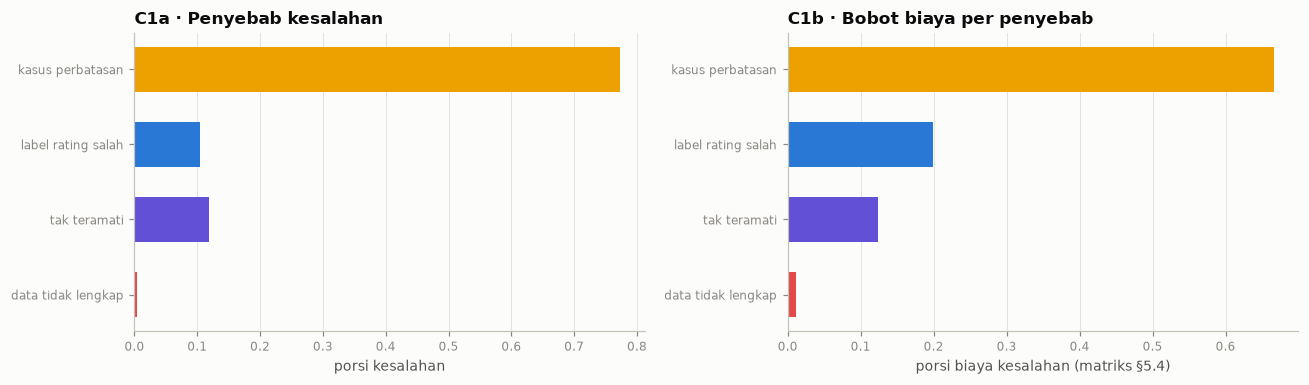

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
order = TAX.index.tolist(); cols = [C['s4'], C['s1'], C['s7'], C['s8']][:len(order)]
ax[0].barh(order[::-1], TAX.porsi_kesalahan[::-1], color=cols[::-1], height=.6); ax[0].set_xlabel('porsi kesalahan'); ax[0].set_title('C1a · Penyebab kesalahan')
ax[1].barh(order[::-1], TAX.porsi_biaya[::-1], color=cols[::-1], height=.6); ax[1].set_xlabel('porsi biaya kesalahan (matriks §5.4)'); ax[1].set_title('C1b · Bobot biaya per penyebab')
for a_ in ax: a_.grid(axis='y', visible=False)
fig.tight_layout(); save_fig(fig, 'C1_error_taxonomy'); plt.show()

### C2. Di mana model gagal secara sistematis? (*slice discovery*)
- Tingkat kesalahan & biaya rata-rata per industri, ukuran, dan laporan.
- **Pohon keputusan dangkal** (kedalaman 3, daun ≥ 30) memprediksi "salah vs benar" dari fitur yang mudah dibaca, sehingga kelompok bermasalah muncul sebagai aturan sederhana.
- Kalibrasi & cakupan conformal per segmen (cek keadilan antar-kelompok).

In [6]:
GRP = pd.concat([LAB.groupby(c).agg(n=('company_id', 'size'), pct_salah=('pred', lambda s: (s != LAB.loc[s.index, 'y']).mean()), biaya_rata2=('biaya', 'mean'),
                                       cakupan_conformal=('conformal_set', lambda s: np.mean([RISK_ORDER[y] in cs for y, cs in zip(LAB.loc[s.index, 'y'], s)])),
                                       P_High_rata2=('p_high', 'mean'), High_aktual=('y', lambda s: (s == 2).mean()))
                 .assign(dimensi=c).rename_axis('nilai').reset_index() for c in ['industry', 'size_class_reference', 'has_report']])
GRP.to_csv(OUT / 'C2_slices.csv', index=False)
display(GRP.sort_values('biaya_rata2', ascending=False).round(3).head(12))
SLICE_FEATS = [c for c in ['size_ord', 'has_report', 'fin_log_der', 'fin_log_cr', 'pay_late_30m', 'tax_late_30m', 'top_buyer_share', 'out_in_12m', 'utilization'] if c in LAB]
Xs = SimpleImputer(strategy='median').fit_transform(LAB[SLICE_FEATS])
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=30, random_state=SEED).fit(Xs, err.values)
print('Aturan kelompok dengan kesalahan tinggi (pohon kedalaman 3; value = [benar, salah]):')
print(export_text(tree, feature_names=SLICE_FEATS, show_weights=True))
leaf = tree.apply(Xs); LEAF = pd.DataFrame({'daun': leaf, 'salah': err.values}).groupby('daun').agg(n=('salah', 'size'), pct_salah=('salah', 'mean')).sort_values('pct_salah', ascending=False)
display(LEAF.head(4).round(3)); print(f'rata-rata tingkat kesalahan: {err.mean():.3f}')

,nilai,n,pct_salah,biaya_rata2,cakupan_conformal,P_High_rata2,High_aktual,dimensi
0,0,1,1.000,5.000,1.000,0.133,1.000,has_report
9,Teknologi informasi,66,0.333,0.561,0.924,0.070,0.091,industry
5,Konstruksi gedung,134,0.313,0.507,0.933,0.175,0.179,industry
0,Aktivitas kesehatan,89,0.348,0.494,0.876,0.079,0.034,industry
2,Industri kimia,59,0.339,0.492,0.864,0.146,0.136,industry
0,Besar,237,0.321,0.473,0.911,0.094,0.089,size_class_reference
4,Industri tekstil & pakaian,100,0.240,0.470,0.940,0.142,0.210,industry
2,Menengah,482,0.290,0.461,0.909,0.142,0.145,size_class_reference
1,1,999,0.295,0.447,0.909,0.137,0.136,has_report
6,Perdagangan besar,189,0.328,0.439,0.884,0.126,0.106,industry


Aturan kelompok dengan kesalahan tinggi (pohon kedalaman 3; value = [benar, salah]):
|--- fin_log_cr <= 0.47
|   |--- out_in_12m <= 0.93
|   |   |--- tax_late_30m <= 0.08
|   |   |   |--- weights: [85.00, 11.00] class: False
|   |   |--- tax_late_30m >  0.08
|   |   |   |--- weights: [66.00, 45.00] class: False
|   |--- out_in_12m >  0.93
|   |   |--- top_buyer_share <= 0.39
|   |   |   |--- weights: [133.00, 144.00] class: True
|   |   |--- top_buyer_share >  0.39
|   |   |   |--- weights: [69.00, 37.00] class: False
|--- fin_log_cr >  0.47
|   |--- top_buyer_share <= 0.39
|   |   |--- fin_log_der <= 0.50
|   |   |   |--- weights: [238.00, 16.00] class: False
|   |   |--- fin_log_der >  0.50
|   |   |   |--- weights: [21.00, 9.00] class: False
|   |--- top_buyer_share >  0.39
|   |   |--- utilization <= 0.45
|   |   |   |--- weights: [48.00, 5.00] class: False
|   |   |--- utilization >  0.45
|   |   |   |--- weights: [44.00, 29.00] class: False



,n,pct_salah
daun,,
6,277,0.520
4,111,0.405
14,73,0.397
7,106,0.349


rata-rata tingkat kesalahan: 0.296


### C3. Apa yang membedakan High yang lolos dari High yang tertangkap? (SHAP)
Kontribusi SHAP P(High) dari NB06 (`shap_values_dev_High.csv.gz`, nasabah dev). Rata-rata SHAP pada **High yang lolos** dibandingkan dengan **High yang tertangkap**: fitur mana yang "menyelamatkan" nasabah berisiko dari flag.

In [7]:
shap_file = IN06 / 'shap_values_dev_High.csv.gz'
if shap_file.exists():
    SH = pd.read_csv(shap_file).set_index('company_id')
    dev = LAB[LAB.pred_source == 'oof'].set_index('company_id')
    hi_miss = dev.index[(dev.y == 2) & (dev.pred != 2)]; hi_hit = dev.index[(dev.y == 2) & (dev.pred == 2)]
    SHC = pd.DataFrame({'SHAP_High_lolos': SH.loc[SH.index.intersection(hi_miss)].mean(), 'SHAP_High_tertangkap': SH.loc[SH.index.intersection(hi_hit)].mean()})
    SHC['selisih'] = SHC.SHAP_High_lolos - SHC.SHAP_High_tertangkap
    SHC = SHC.reindex(SHC.selisih.abs().sort_values(ascending=False).index); SHC.to_csv(OUT / 'C3_shap_missed_vs_caught.csv')
    print(f'High lolos: {len(hi_miss)} · High tertangkap: {len(hi_hit)} (dev)'); display(SHC.head(8).round(3))
else:
    print('shap_values_dev_High.csv.gz tidak ada — jalankan NB06 bagian B5')

High lolos: 10 · High tertangkap: 99 (dev)


,SHAP_High_lolos,SHAP_High_tertangkap,selisih
fin_log_der,-0.136,0.713,-0.849
fin_log_cr,-0.225,0.482,-0.706
top_buyer_share,-0.089,0.244,-0.334
capture_ratio,0.148,-0.014,0.162
fin_npm,-0.041,0.102,-0.142
pay_late_30m,0.014,0.141,-0.127
tax_late_30m,0.023,0.141,-0.117
inflow_cv_sa,0.177,0.062,0.115


## D. Audit label rating (*confident learning*)
Prinsip (Northcutt dkk., 2021): label dicurigai salah bila model **yakin** pada kelas lain. Ambang per kelas t_j = rata-rata P(j) pada nasabah berlabel j; label l dicurigai bila ada kelas j ≠ l dengan P(j) ≥ t_j dan P(j) > P(l). Antrean diurutkan menurut selisih max P(j) − P(l).

Probabilitas yang dipakai adalah **out-of-sample** (OOF untuk dev, model final untuk test). Karena GT sudah terbuka, ketepatan antrean bisa diukur: berapa banyak yang benar-benar label salah, dibanding acak (base rate ±4–5%).

Hasilnya adalah **daftar audit untuk analis rating**, bukan untuk membuang data latih. Riwayat proyek (v6) menunjukkan membuang label yang dicurigai justru menurunkan F1.

In [8]:
y_lab = LAB.y.values; t_j = np.array([P_LAB[y_lab == j, j].mean() for j in range(3)])
P_other = P_LAB.copy(); P_other[np.arange(len(P_LAB)), y_lab] = -1
j_best = P_other.argmax(1); margin = P_other.max(1) - P_LAB[np.arange(len(P_LAB)), y_lab]
suspect = (P_other.max(1) >= t_j[j_best]) & (margin > 0)
AUD = LAB[['company_id', 'split', 'industry', 'risk_class', 'pred_class', 'p_low', 'p_medium', 'p_high', 'reason_1', 'reason_2']].copy()
AUD['kelas_usulan'] = [RISK_ORDER[j] for j in j_best]; AUD['skor_curiga'] = np.where(suspect, margin, -np.inf); AUD['label_salah_GT'] = LAB.flip.values
AUD = AUD.sort_values('skor_curiga', ascending=False).reset_index(drop=True)
base = LAB.flip.mean(); rows = []
for k in AUDIT_K:
    q = AUD.head(k); rows.append({'antrean_top_k': k, 'label_salah_ditemukan': int(q.label_salah_GT.sum()), 'presisi': q.label_salah_GT.mean(),
                                  'acak_harapan': k * base, 'lift': q.label_salah_GT.mean() / base, 'recall_label_salah': q.label_salah_GT.sum() / LAB.flip.sum()})
if HAS_CLEANLAB:
    idx = find_label_issues(y_lab, P_LAB, return_indices_ranked_by='self_confidence')
    for k in AUDIT_K:
        sel = LAB.flip.values[idx[:k]]; rows.append({'antrean_top_k': f'{k} (cleanlab)', 'label_salah_ditemukan': int(sel.sum()), 'presisi': sel.mean(),
                                                     'acak_harapan': k * base, 'lift': sel.mean() / base, 'recall_label_salah': sel.sum() / LAB.flip.sum()})
AUDIT = pd.DataFrame(rows); AUDIT.to_csv(OUT / 'D_label_audit_precision.csv', index=False); display(AUDIT.round(3))
AUD[np.isfinite(AUD.skor_curiga)].drop(columns='label_salah_GT').to_csv(OUT / 'label_audit_queue.csv', index=False)
print(f'antrean audit: {np.isfinite(AUD.skor_curiga).sum()} label dicurigai → outputs/07_postevaluation/label_audit_queue.csv (tanpa kolom GT)')

,antrean_top_k,label_salah_ditemukan,presisi,acak_harapan,lift,recall_label_salah
0,30,19,0.633,1.32,14.394,0.432
1,50,23,0.460,2.20,10.455,0.523
2,100,27,0.270,4.40,6.136,0.614


antrean audit: 151 label dicurigai → outputs/07_postevaluation/label_audit_queue.csv (tanpa kolom GT)


## E. Koreksi keputusan untuk prospect (pasca-evaluasi)
### E1. Diagnosis
Di NB06, prospect di-flag High 54% sedangkan yang High sebenarnya 29%. Ada dua kemungkinan penyebab, dan keduanya bisa diukur **tanpa label prospect**:
- **Titik operasi**: ambang P(High) dipilih untuk recall 90% pada *nasabah*. Pada prospect, daya pisah model lebih lemah (fitur transaksi tidak ada), sehingga ambang yang sama menghasilkan jauh lebih banyak flag.
- **Pergeseran prior**: proporsi High prospect memang berbeda dari nasabah (13,6%).

Prior prospect diperkirakan tanpa label dengan dua cara:
- **EM** (Saerens dkk., 2002): penyesuaian iteratif posterior & prior;
- **BBSE** (Lipton dkk., 2018): matriks kebingungan di dev × distribusi prediksi prospect.

In [9]:
# OOF model prospect (IW) di dev — prosedur identik dengan NB06
DEV = RISK[RISK.split.isin(['train', 'valid'])].reset_index(drop=True); y_dev = DEV.risk_class.map(Y_MAP).astype(int).values
PROS = RISK[RISK.customer_type == 'Prospect'].reset_index(drop=True); y_pros = PROS.company_id.map(GT_P.true_risk_class).map(Y_MAP).astype(int).values
if (RAW / 'companies.csv').exists():
    co = pd.read_csv(RAW / 'companies.csv', usecols=lambda c: c in ('company_id', 'business_group')).set_index('company_id')
    GROUPS = co.business_group.reindex(DEV.company_id).fillna(pd.Series(DEV.company_id.values, index=DEV.company_id.values)).values
else:
    GROUPS = DEV.company_id.values
FOLDS = list(StratifiedGroupKFold(5, shuffle=True, random_state=SEED + 11).split(DEV, y_dev, GROUPS))
pw = MAN['prospect']; RATIO = pw['ratio']
def iw(p): return np.clip((p / (1 - p) * RATIO) ** pw['iw_power'], *pw['iw_clip'])
DOM_X = pd.concat([DEV, PROS], ignore_index=True); DOM_y = np.r_[np.zeros(len(DEV)), np.ones(len(PROS))].astype(int)
dom = lambda: make_pipeline(make_prep(FEATURE_SETS['set_prospect']), SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True),
                            StandardScaler(), LogisticRegression(C=0.3, max_iter=5000))
p_dom = np.zeros(len(DOM_X))
for tr, va in StratifiedKFold(5, shuffle=True, random_state=SEED).split(DOM_X, DOM_y):
    p_dom[va] = dom().fit(DOM_X.iloc[tr], DOM_y[tr]).predict_proba(DOM_X.iloc[va])[:, 1]
W_DEV = iw(p_dom[:len(DEV)])
spec_p = dict(kind=MAN['basis'], cols=FEATURE_SETS['set_prospect'], params=MAN['hiperparameter'], weighting=MAN['penyeimbangan'])
P_raw = np.zeros((len(DEV), 3))
for tr, va in FOLDS:
    P_raw[va] = RiskModel(spec_p['kind'], spec_p['cols'], spec_p['params'], spec_p['weighting'], SEED).fit(DEV.iloc[tr], y_dev[tr], sample_weight=W_DEV[tr]).predict_proba(DEV.iloc[va])
Q_dev = crossfit_calibrate(P_raw, y_dev, FOLDS, MAN['kalibrasi'])
T_PROS = MAN['aturan_keputusan']['set_prospect']['ambang_P_High']
PM = joblib.load(M06 / 'champion__set_prospect.joblib'); Q_pros = PM.predict_proba(PROS)
print(f'AUC P(High) di dev (OOF, model prospect): {roc_auc_score(y_dev == 2, Q_dev[:, 2]):.3f} · ambang NB06 {T_PROS:.3f} · '
      f'rata-rata P(High) prospect {Q_pros[:, 2].mean():.3f} vs dev {Q_dev[:, 2].mean():.3f}')

pi_tr = np.bincount(y_dev, minlength=3) / len(y_dev)
def em_prior(P, pi_tr, n_iter=200, tol=1e-8):
    pi = pi_tr.copy()
    for _ in range(n_iter):
        A = P * (pi / pi_tr); A /= A.sum(1, keepdims=True); new = A.mean(0)
        if np.abs(new - pi).max() < tol: break
        pi = new
    return pi, A
pi_em, Q_pros_em = em_prior(Q_pros, pi_tr)
Cm = np.zeros((3, 3)); pred_dev_arg = Q_dev.argmax(1)
for j in range(3): Cm[:, j] = np.bincount(pred_dev_arg[y_dev == j], minlength=3) / max((y_dev == j).sum(), 1)
mu = np.bincount(Q_pros.argmax(1), minlength=3) / len(Q_pros)
pi_bbse = np.clip(np.linalg.lstsq(Cm, mu, rcond=None)[0], 0, None); pi_bbse /= pi_bbse.sum()
PRIOR = pd.DataFrame({'nasabah dev (label)': pi_tr, 'prospect: EM': pi_em, 'prospect: BBSE': pi_bbse, 'prospect: rata-rata P terkalibrasi': Q_pros.mean(0)}, index=RISK_ORDER)
PRIOR.to_csv(OUT / 'E1_prospect_prior_estimates.csv'); display(PRIOR.round(3))

AUC P(High) di dev (OOF, model prospect): 0.933 · ambang NB06 0.106 · rata-rata P(High) prospect 0.321 vs dev 0.137


,nasabah dev (label),prospect: EM,prospect: BBSE,prospect: rata-rata P terkalibrasi
Low,0.614,0.347,0.406,0.442
Medium,0.250,0.120,0.027,0.237
High,0.136,0.533,0.567,0.321


### E2. Varian aturan keputusan untuk prospect (semuanya tanpa label prospect)
| Varian | Probabilitas | Keputusan High |
|---|---|---|
| V0 NB06 | terkalibrasi (dev) | ambang recall 90% nasabah |
| V1 biaya | terkalibrasi (dev) | **keputusan Bayes**: kelas dengan biaya harapan terkecil (matriks §5.4), tanpa syarat recall |
| V2 EM + biaya | disesuaikan ke prior EM | keputusan Bayes |
| V3 recall 80% | terkalibrasi (dev) | ambang recall 80% (dari OOF prospect-model di dev) |
| V4 EM + estimasi recall 90% | disesuaikan ke prior EM | ambang terbesar dengan **estimasi** recall High ≥ 90% (Σ P(High) yang di-flag ÷ Σ P(High)) |

### E3. Aturan pilih (tanpa label prospect)
1. **Cek asumsi label shift.** EM dan BBSE hanya sah bila yang bergeser cuma proporsi kelas. Bila taksiran prior High dari EM melebihi rata-rata P(High) terkalibrasi prospect lebih dari 0,10, asumsi itu dianggap **gugur** (prospect juga berbeda fitur, C2ST AUC ±0,79) dan varian EM (V2, V4) **tidak dipakai**.
2. Bila asumsi gugur → usulan = **V1 keputusan biaya**: kelas dengan biaya harapan terkecil pada probabilitas terkalibrasi (Elkan, 2001). Alasannya teori keputusan: ambang recall 90% dirancang untuk memantau nasabah yang sudah punya eksposur; untuk prospect, keputusan Bayes dengan probabilitas terkalibrasi meminimalkan biaya harapan.
3. Bila asumsi bertahan → varian dengan estimasi biaya terkecil di bawah posterior EM, dengan estimasi recall High ≥ 85%.

*Catatan proses (transparansi):* versi awal aturan ini langsung memakai estimasi biaya di bawah posterior EM. Pada uji coba, aturan itu memilih varian EM yang ternyata memperburuk hasil terhadap GT, karena asumsi label shift tidak terpenuhi. Langkah 1 ditambahkan **setelah** uji coba itu, jadi pilihan prospect di notebook ini sepenuhnya berstatus pasca-evaluasi dan harus divalidasi di batch prospect berikutnya.

In [10]:
def thr_recall_dev(target):
    ph = np.sort(Q_dev[y_dev == 2, 2])[::-1]; return ph[int(np.ceil(target * len(ph))) - 1]
def bayes(P): return (P @ COST).argmin(1)
def thr_expected_recall(P, target):
    o = np.argsort(-P[:, 2]); cs = np.cumsum(P[o, 2]) / P[:, 2].sum(); k = np.searchsorted(cs, target); return P[o[min(k, len(o) - 1)], 2]
VARIANTS = {
    'V0 NB06 (recall 90% nasabah)': decide(Q_pros, T_PROS),
    'V1 keputusan biaya': bayes(Q_pros),
    'V2 EM + keputusan biaya': bayes(Q_pros_em),
    'V3 ambang recall 80%': decide(Q_pros, thr_recall_dev(0.80)),
    'V4 EM + estimasi recall 90%': decide(Q_pros_em, thr_expected_recall(Q_pros_em, 0.90)),
}
rows = []
for nm, pred in VARIANTS.items():
    exp_cost = (Q_pros_em * COST[:, pred].T).sum(1).sum()            # Σ_i Σ_k P_EM(k|x_i) · COST[k, pred_i]
    exp_rec = Q_pros_em[pred == 2, 2].sum() / Q_pros_em[:, 2].sum()
    rows.append({'varian': nm, '% flag High': 100 * (pred == 2).mean(), 'estimasi_biaya': exp_cost, 'estimasi_recall_High': exp_rec})
SEL = pd.DataFrame(rows).set_index('varian')
gap = pi_em[2] - Q_pros[:, 2].mean()
LABEL_SHIFT_OK = gap <= 0.10
if LABEL_SHIFT_OK:
    eligible = SEL[SEL.estimasi_recall_High >= PROSPECT_MIN_RECALL]
    CHOSEN = eligible.estimasi_biaya.idxmin() if len(eligible) else 'V0 NB06 (recall 90% nasabah)'
else:
    CHOSEN = 'V1 keputusan biaya'
SEL['dipilih_tanpa_label'] = SEL.index == CHOSEN; SEL.to_csv(OUT / 'E3_prospect_variant_selection.csv')
display(SEL.round(3))
print(f'prior High EM {pi_em[2]:.3f} vs rata-rata P(High) terkalibrasi {Q_pros[:, 2].mean():.3f} (selisih {gap:+.3f}) → asumsi label shift '
      f'{"bertahan" if LABEL_SHIFT_OK else "GUGUR — varian EM tidak dipakai"}')
print(f'→ dipilih tanpa label prospect: {CHOSEN}')

,% flag High,estimasi_biaya,estimasi_recall_High,dipilih_tanpa_label
varian,,,,
V0 NB06 (recall 90% nasabah),53.500,432.841,0.861,False
V1 keputusan biaya,47.333,514.190,0.799,True
V2 EM + keputusan biaya,71.667,329.188,0.966,False
V3 ambang recall 80%,44.833,556.574,0.769,False
V4 EM + estimasi recall 90%,58.500,376.371,0.900,False


prior High EM 0.533 vs rata-rata P(High) terkalibrasi 0.321 (selisih +0.212) → asumsi label shift GUGUR — varian EM tidak dipakai
→ dipilih tanpa label prospect: V1 keputusan biaya


### E4. Laporan terhadap ground truth prospect (pasca-evaluasi)
Label prospect **baru dibaca di sini**, setelah pilihan E3 terkunci. Semua varian dilaporkan agar terlihat apakah aturan pilih tanpa label juga baik terhadap kebenaran.

,macro_F1,recall_High,presisi_High,% flag High,biaya_sebenarnya,High_terlewat,dipilih,% High sebenarnya
varian,,,,,,,,
V0 NB06 (recall 90% nasabah),0.566,0.960,0.517,53.500,347,7,False,28.833
V1 keputusan biaya,0.591,0.913,0.556,47.333,358,15,True,28.833
V2 EM + keputusan biaya,0.418,0.994,0.400,71.667,423,1,False,28.833
V3 ambang recall 80%,0.600,0.890,0.572,44.833,367,19,False,28.833
V4 EM + estimasi recall 90%,0.516,0.983,0.484,58.500,356,3,False,28.833


Diagnosis: rata-rata P(High) terkalibrasi prospect 32.1% vs High sebenarnya 28.8% (taksiran EM 53.3%, BBSE 56.7%) → yang berlebihan terutama ambang keputusan, bukan probabilitasnya.
Pilihan tanpa label (V1 keputusan biaya): flag High 54% → 47%, presisi High 0.52 → 0.56, recall High 0.96 → 0.91, biaya 347 → 358


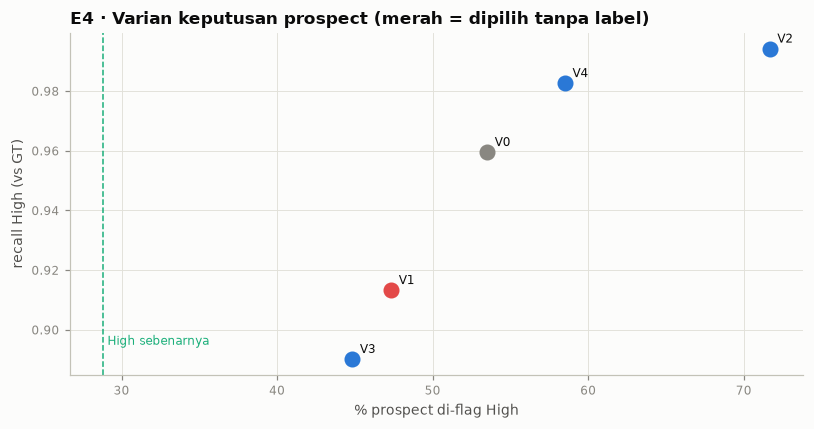

In [11]:
CHOSEN_LOCKED = CHOSEN
rows = []
for nm, pred in VARIANTS.items():
    rows.append({'varian': nm, 'macro_F1': macro_f1(y_pros, pred), 'recall_High': recall_high(y_pros, pred),
                 'presisi_High': ((pred == 2) & (y_pros == 2)).sum() / max((pred == 2).sum(), 1), '% flag High': 100 * (pred == 2).mean(),
                 'biaya_sebenarnya': int(row_cost(y_pros, pred).sum()), 'High_terlewat': int(((y_pros == 2) & (pred != 2)).sum()), 'dipilih': nm == CHOSEN_LOCKED})
PGT = pd.DataFrame(rows).set_index('varian'); PGT['% High sebenarnya'] = 100 * (y_pros == 2).mean()
PGT.to_csv(OUT / 'E4_prospect_variants_vs_GT.csv'); display(PGT.round(3))
print(f'Diagnosis: rata-rata P(High) terkalibrasi prospect {Q_pros[:, 2].mean():.1%} vs High sebenarnya {(y_pros == 2).mean():.1%} '
      f'(taksiran EM {pi_em[2]:.1%}, BBSE {pi_bbse[2]:.1%}) → yang berlebihan terutama ambang keputusan, bukan probabilitasnya.')
v0, vc = PGT.iloc[0], PGT.loc[CHOSEN_LOCKED]
print(f'Pilihan tanpa label ({CHOSEN_LOCKED}): flag High {v0["% flag High"]:.0f}% → {vc["% flag High"]:.0f}%, presisi High {v0.presisi_High:.2f} → {vc.presisi_High:.2f}, '
      f'recall High {v0.recall_High:.2f} → {vc.recall_High:.2f}, biaya {int(v0.biaya_sebenarnya)} → {int(vc.biaya_sebenarnya)}')

fig, ax = plt.subplots(figsize=(7.5, 4))
for nm, r in PGT.iterrows():
    col = C['s8'] if r.dipilih else (C['muted'] if nm.startswith('V0') else C['s1'])
    ax.scatter(r['% flag High'], r.recall_High, s=90, color=col, zorder=3); ax.annotate(nm.split(' ')[0], (r['% flag High'], r.recall_High), xytext=(5, 4), textcoords='offset points', fontsize=8)
ax.axvline(PGT['% High sebenarnya'].iloc[0], color=C['s3'], ls='--', lw=1); ax.text(PGT['% High sebenarnya'].iloc[0], ax.get_ylim()[0] + .01, ' High sebenarnya', color=C['s3'], fontsize=8)
ax.set_xlabel('% prospect di-flag High'); ax.set_ylabel('recall High (vs GT)'); ax.set_title('E4 · Varian keputusan prospect (merah = dipilih tanpa label)')
fig.tight_layout(); save_fig(fig, 'E4_prospect_variants'); plt.show()

PROS_SHADOW = pd.DataFrame({'company_id': PROS.company_id, 'p_high_NB06': Q_pros[:, 2].round(4), 'p_high_EM': Q_pros_em[:, 2].round(4),
                            'pred_class_NB06': [RISK_ORDER[k] for k in VARIANTS['V0 NB06 (recall 90% nasabah)']],
                            'pred_class_shadow': [RISK_ORDER[k] for k in VARIANTS[CHOSEN_LOCKED]], 'aturan_shadow': CHOSEN_LOCKED, 'status': 'shadow (pasca-evaluasi)'})
PROS_SHADOW.to_csv(SCORES / 'prospect_decision_shadow_nb07.csv', index=False)

## F. Perbaikan aturan anomali (pasca-evaluasi)
Grid kecil per jenis kejadian, dinilai di **perusahaan non-test**:
- **Pembeli keluar**: ambang `buyer_exit_share` 0,15 / 0,20 / 0,25 / 0,30.
- **Distress**: sinyal timing wajib **dikonfirmasi arus kas** (`out_in_delta` ≥ x atau `cusum_down` ≥ y).
- **Erosi wallet**: persentil penurunan 2% / 5% / 10%, dengan / tanpa syarat `capture_chg_6m` (sering kosong karena lag laporan).

**Aturan pilih** (ditetapkan sebelum grid):
- pembeli keluar & distress → presisi alarm baru tertinggi, dengan recall kejadian turun ≤ 0,05 (distress: % lead ≥ 1 bln juga turun ≤ 0,05);
- erosi wallet → recall dini tertinggi, dengan presisi turun ≤ 0,05.

In [13]:
PANEL = load_features(PROJECT_ROOT, 'anomaly'); R1 = AR.load_rules(M06 / 'anomaly_rules.json')
for k, v in AR.DEFAULT_RULES.items():                                  # kunci baru (v2) dengan nilai default
    if isinstance(v, dict): R1.setdefault(k, {}); [R1[k].setdefault(kk, vv) for kk, vv in v.items()]
P2 = PANEL[PANEL.ym >= R1['start_month']]; MONTHS = sorted(P2.ym.unique())
TEST_F = set(RISK.company_id[RISK.split == 'test']); NONTEST_F = set(P2.company_id) - TEST_F
def eval_type(R, typ, firms=NONTEST_F, k=R1['k_top']):
    A = AR.apply_rules(PANEL, R, with_reason=False); Rt, O, _ = AR.evaluate_alerts(A, EV, firms, MONTHS, k_top=k)
    Rt = Rt.set_index('jenis')
    return (Rt.loc[typ].to_dict() if typ in Rt.index else {c: np.nan for c in Rt.columns}), O
t0 = time.time(); GRID = []
def variants(typ):
    if typ == 'buyer_exit':
        return [{'buyer_exit_share_min': v} for v in (0.15, 0.20, 0.25, 0.30)]
    if typ == 'distress':
        return [{'confirm_out_in_delta_min': a, 'confirm_cusum_down_min': b} for a in (None, 0.0, 0.05, 0.10) for b in (None, 2.0, 4.0)]
    return [{'chg_3v6_monthly_pct_max': p, 'capture_chg_6m_le': c} for p in (0.02, 0.05, 0.10) for c in (0.0, None)]
BEST = {}
for typ in ['buyer_exit', 'distress', 'wallet_erosion']:
    base_m, _ = eval_type(R1, typ); cand = []
    for v in variants(typ):
        R = copy.deepcopy(R1); R[typ].update(v); m, _ = eval_type(R, typ)
        cand.append({'jenis': typ, 'varian': json.dumps(v), **m}); GRID.append(cand[-1])
    cd = pd.DataFrame(cand)
    if typ == 'wallet_erosion':
        ok = cd[cd.presisi_alarm_baru >= base_m['presisi_alarm_baru'] - ANOM_LOSS_TOL]; best = ok.sort_values(['recall_dini', 'presisi_alarm_baru'], ascending=False).iloc[0]
    else:
        ok = cd[cd.recall_kejadian >= base_m['recall_kejadian'] - ANOM_LOSS_TOL]
        if typ == 'distress': ok = ok[ok.pct_lead_ge_1bln.fillna(0) >= np.nan_to_num(base_m['pct_lead_ge_1bln']) - ANOM_LOSS_TOL]
        best = ok.sort_values('presisi_alarm_baru', ascending=False).iloc[0] if len(ok) else cd.iloc[0]
    BEST[typ] = json.loads(best.varian)
GRID = pd.DataFrame(GRID); GRID.to_csv(OUT / 'F_anomaly_grid_nontest.csv', index=False)
print(f'grid {len(GRID)} varian dalam {time.time() - t0:.0f} dtk'); print('terpilih (non-test):', BEST)
display(GRID[['jenis', 'varian', 'alarm_baru_per_bulan', 'presisi_alarm_baru', 'recall_kejadian', 'recall_dini', 'pct_lead_ge_1bln']].round(3))

grid 22 varian dalam 5 dtk
terpilih (non-test): {'buyer_exit': {'buyer_exit_share_min': 0.2}, 'distress': {'confirm_out_in_delta_min': None, 'confirm_cusum_down_min': None}, 'wallet_erosion': {'chg_3v6_monthly_pct_max': 0.02, 'capture_chg_6m_le': 0.0}}


,jenis,varian,alarm_baru_per_bulan,presisi_alarm_baru,recall_kejadian,recall_dini,pct_lead_ge_1bln
0,buyer_exit,"{""buyer_exit_share_min"": 0.15}",26.500,0.088,0.963,0.963,NaN
1,buyer_exit,"{""buyer_exit_share_min"": 0.2}",14.500,0.152,0.926,0.926,NaN
2,buyer_exit,"{""buyer_exit_share_min"": 0.25}",8.000,0.240,0.833,0.815,NaN
3,buyer_exit,"{""buyer_exit_share_min"": 0.3}",4.875,0.316,0.667,0.667,NaN
4,distress,"{""confirm_out_in_delta_min"": null, ""confirm_cusum_down_min"": null}",37.583,0.081,1.000,1.000,0.738
5,distress,"{""confirm_out_in_delta_min"": null, ""confirm_cusum_down_min"": 2.0}",12.708,0.203,0.800,0.585,0.342
6,distress,"{""confirm_out_in_delta_min"": null, ""confirm_cusum_down_min"": 4.0}",6.875,0.285,0.677,0.354,0.304
7,distress,"{""confirm_out_in_delta_min"": 0.0, ""confirm_cusum_down_min"": null}",18.208,0.101,0.492,0.138,0.500
8,distress,"{""confirm_out_in_delta_min"": 0.0, ""confirm_cusum_down_min"": 2.0}",23.833,0.128,0.892,0.646,0.372
9,distress,"{""confirm_out_in_delta_min"": 0.0, ""confirm_cusum_down_min"": 4.0}",20.792,0.130,0.831,0.431,0.414


In [14]:
R2 = copy.deepcopy(R1); R2['version'] = 'anomaly-rules-v2 (NB07, pasca-evaluasi, shadow)'
for typ, v in BEST.items(): R2[typ].update(v)
AR.save_rules(R2, M07 / 'anomaly_rules_v2.json')
A1, A2 = AR.apply_rules(PANEL, R1), AR.apply_rules(PANEL, R2)
K_TEST = max(1, round(R1['k_top'] * len(TEST_F & set(P2.company_id)) / len(NONTEST_F)))
rows, by = [], []
for ver, A in [('v1 (NB04/NB06, resmi)', A1), ('v2 (NB07, shadow)', A2)]:
    for grp, firms, k in [('non-test (pemilihan)', NONTEST_F, R1['k_top']), ('test (laporan)', TEST_F, K_TEST)]:
        Rt, O, _ = AR.evaluate_alerts(A, EV, firms, MONTHS, k_top=k); rows.append({'versi': ver, 'kelompok': grp, **O}); by.append(Rt.assign(versi=ver, kelompok=grp))
ANOM_CMP = pd.DataFrame(rows); ANOM_BY = pd.concat(by); ANOM_CMP.to_csv(OUT / 'F_anomaly_v1_vs_v2.csv', index=False); ANOM_BY.to_csv(OUT / 'F_anomaly_v1_vs_v2_by_type.csv', index=False)
display(ANOM_CMP.set_index(['kelompok', 'versi'])[['k', 'alarm_baru_per_bulan', 'presisi_top_k', 'presisi_top_k_jenis_apa_pun', 'alarm_palsu_per_100_nasabah_per_bulan',
                                                   'lead_median_distress', 'pct_distress_lead_ge_1bln']].round(3))
display(ANOM_BY[ANOM_BY.jenis.isin(BEST)].pivot_table(index=['jenis', 'kelompok'], columns='versi', values=['presisi_alarm_baru', 'recall_kejadian', 'recall_dini']).round(3))
A2.assign(champion_or_shadow='shadow (v2 NB07)').to_csv(SCORES / 'anomaly_alerts_v2_shadow.csv', index=False)

,,k,alarm_baru_per_bulan,presisi_top_k,presisi_top_k_jenis_apa_pun,alarm_palsu_per_100_nasabah_per_bulan,lead_median_distress,pct_distress_lead_ge_1bln
kelompok,versi,,,,,,,
non-test (pemilihan),"v1 (NB04/NB06, resmi)",30,102.083,0.304,0.475,5.750,1.0,0.738
test (laporan),"v1 (NB04/NB06, resmi)",5,18.375,0.342,0.558,5.750,0.0,0.375
non-test (pemilihan),"v2 (NB07, shadow)",30,90.083,0.301,0.469,4.986,1.0,0.738
test (laporan),"v2 (NB07, shadow)",5,16.083,0.342,0.550,4.875,0.0,0.375


presisi_alarm_baru                             recall_dini                         recall_kejadian                  
versi                               v1 (NB04/NB06, resmi) v2 (NB07, shadow) v1 (NB04/NB06, resmi) v2 (NB07, shadow) v1 (NB04/NB06, resmi) v2 (NB07, shadow)
jenis          kelompok                                                                                                                                    
buyer_exit     non-test (pemilihan)                 0.088             0.152                 0.963             0.926                 0.963             0.926
               test (laporan)                       0.077             0.133                 1.000             1.000                 1.000             1.000
distress       non-test (pemilihan)                 0.081             0.081                 1.000             1.000                 1.000             1.000
               test (laporan)                       0.074             0.074                 1.000             1.000                 1.000             1.000
wallet_erosion non-test (pemilihan)                 0.279             0.279                 0.013             0.013                 0.756             0.756
               test (laporan)                       0.182             0.182                 0.111             0.111                 0.778             0.778

## G. Ringkasan & tata kelola
Semua perbaikan berstatus **shadow**: dashboard tetap menampilkan keputusan resmi NB06; versi NB07 ditampilkan di halaman audit sebagai "usulan perbaikan", dan baru dipromosikan setelah dinilai di data segar.

In [15]:
verify_nb06()
REG = pd.DataFrame([
    {'komponen': 'risiko nasabah kredit', 'versi resmi': 'XGBoost NB06', 'usulan NB07': '— (tidak diubah)', 'status usulan': '-', 'dasar': 'analisis kesalahan C1–C3'},
    {'komponen': 'keputusan prospect', 'versi resmi': 'V0 ambang recall 90% nasabah', 'usulan NB07': CHOSEN_LOCKED, 'status usulan': 'shadow (pasca-evaluasi)',
     'dasar': f'aturan tanpa label (cek label shift → keputusan biaya); GT: flag {v0["% flag High"]:.0f}% → {vc["% flag High"]:.0f}%, presisi {v0.presisi_High:.2f} → {vc.presisi_High:.2f}'},
    {'komponen': 'aturan anomali', 'versi resmi': R1.get('version', 'v1'), 'usulan NB07': json.dumps(BEST), 'status usulan': 'shadow (pasca-evaluasi)', 'dasar': 'grid di non-test, laporan di test'},
    {'komponen': 'audit label rating', 'versi resmi': '-', 'usulan NB07': f'antrean {np.isfinite(AUD.skor_curiga).sum()} label', 'status usulan': 'alat bantu analis',
     'dasar': f'top-30 presisi {AUDIT.iloc[0].presisi:.0%} vs acak {base:.0%}'},
])
REG.to_csv(OUT / 'G_postevaluation_registry.csv', index=False); display(REG)
top_cause = TAX.index[0]
a1t = ANOM_CMP[(ANOM_CMP.versi.str.startswith('v1')) & (ANOM_CMP.kelompok.str.startswith('test'))].iloc[0]
a2t = ANOM_CMP[(ANOM_CMP.versi.str.startswith('v2')) & (ANOM_CMP.kelompok.str.startswith('test'))].iloc[0]
SUMMARY = f"""
**Analisis kesalahan (1.000 nasabah kredit):** {err.sum()} kesalahan; penyebab terbesar menurut biaya: **{top_cause}** ({TAX.loc[top_cause, 'porsi_biaya']:.0%} biaya).
Porsi per penyebab: {', '.join(f'{i} {r.porsi_kesalahan:.0%}' for i, r in TAX.iterrows())}. **{safety:.0%} kesalahan masuk antrean Review analis** (jaring pengaman).
**Audit label:** top-30 antrean memuat {int(AUDIT.iloc[0].label_salah_ditemukan)} label yang benar-benar salah (presisi {AUDIT.iloc[0].presisi:.0%}, {AUDIT.iloc[0].lift:.1f}× acak).
**Prospect (shadow):** aturan dipilih tanpa label = {CHOSEN_LOCKED}. Terhadap GT: flag High {v0['% flag High']:.0f}% → {vc['% flag High']:.0f}% (sebenarnya {vc['% High sebenarnya']:.0f}%), presisi High {v0.presisi_High:.2f} → {vc.presisi_High:.2f}, recall {v0.recall_High:.2f} → {vc.recall_High:.2f}, biaya {int(v0.biaya_sebenarnya)} → {int(vc.biaya_sebenarnya)}.
**Anomali (shadow):** {BEST}. Test: presisi top-{K_TEST} {a1t.presisi_top_k:.0%} → {a2t.presisi_top_k:.0%}; alarm palsu/100/bln {a1t.alarm_palsu_per_100_nasabah_per_bulan:.2f} → {a2t.alarm_palsu_per_100_nasabah_per_bulan:.2f}.
*Semua usulan berstatus shadow (pasca-evaluasi); angka resmi tetap NB06.*
"""
display(Markdown(SUMMARY)); (OUT / 'SUMMARY.md').write_text(SUMMARY, encoding='utf-8')
print(f'total waktu jalan: {(time.time() - T0) / 60:.1f} menit')

,komponen,versi resmi,usulan NB07,status usulan,dasar
0,risiko nasabah kredit,XGBoost NB06,— (tidak diubah),-,analisis kesalahan C1–C3
1,keputusan prospect,V0 ambang recall 90% nasabah,V1 keputusan biaya,shadow (pasca-evaluasi),"aturan tanpa label (cek label shift → keputusan biaya); GT: flag 54% → 47%, presisi 0...."
2,aturan anomali,anomaly-rules-v1 (NB04),"{""buyer_exit"": {""buyer_exit_share_min"": 0.2}, ""distress"": {""confirm_out_in_delta_min"":...",shadow (pasca-evaluasi),"grid di non-test, laporan di test"
3,audit label rating,-,antrean 151 label,alat bantu analis,top-30 presisi 63% vs acak 4%



**Analisis kesalahan (1.000 nasabah kredit):** 296 kesalahan; penyebab terbesar menurut biaya: **kasus perbatasan** (67% biaya).
Porsi per penyebab: kasus perbatasan 77%, label rating salah 10%, tak teramati 12%, data tidak lengkap 0%. **77% kesalahan masuk antrean Review analis** (jaring pengaman).
**Audit label:** top-30 antrean memuat 19 label yang benar-benar salah (presisi 63%, 14.4× acak).
**Prospect (shadow):** aturan dipilih tanpa label = V1 keputusan biaya. Terhadap GT: flag High 54% → 47% (sebenarnya 29%), presisi High 0.52 → 0.56, recall 0.96 → 0.91, biaya 347 → 358.
**Anomali (shadow):** {'buyer_exit': {'buyer_exit_share_min': 0.2}, 'distress': {'confirm_out_in_delta_min': None, 'confirm_cusum_down_min': None}, 'wallet_erosion': {'chg_3v6_monthly_pct_max': 0.02, 'capture_chg_6m_le': 0.0}}. Test: presisi top-5 34% → 34%; alarm palsu/100/bln 5.75 → 4.88.
*Semua usulan berstatus shadow (pasca-evaluasi); angka resmi tetap NB06.*


total waktu jalan: 1.0 menit


## Daftar pustaka
| Kunci | Rujukan | Untuk | Status |
|---|---|---|---|
| Northcutt2021 | Northcutt, C., Jiang, L. & Chuang, I. (2021). Confident learning. *JAIR*, 70. doi:10.1613/jair.1.12125 | audit label | ✔ |
| Saerens2002 | Saerens, M., Latinne, P. & Decaestecker, C. (2002). Adjusting the outputs of a classifier to new a priori probabilities. *Neural Computation*, 14(1) | prior EM prospect | ○ |
| Lipton2018 | Lipton, Z., Wang, Y.-X. & Smola, A. (2018). Detecting and correcting for label shift with black box predictors. *ICML* | BBSE | ○ |
| Elkan2001 | Elkan, C. (2001). The foundations of cost-sensitive learning. *IJCAI* | keputusan biaya | ○ |
| Chung2019 | Chung, Y. dkk. (2019). Slice finder: Automated data slicing for model validation. *ICDE* | slice discovery | ○ |
| Wu2021 | Wu, R. & Keogh, E. (2021). *IEEE TKDE*. doi:10.1109/TKDE.2021.3112126 | aturan anomali | ✔ |
| Cawley2010 | Cawley & Talbot (2010). *JMLR*, 11 | pasca-evaluasi ≠ test resmi | ✔ |

✔ = sudah dicocokkan ke Crossref/penerbit; ○ = cek sebelum dikutip di slide.